In [1]:
import gc
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from pybonsai import BonsaiOutput
from scipy.spatial.distance import squareform

import bonsai_loop as bl
from bonsai_loop.bonsai_lib import (
    bonsai_clustering,
    get_pdists_on_tree,
    get_pdists_posterior,
)

sc.set_figure_params(figsize=(5, 5))
data_dir = Path("../data")

/home/stan/Git/bonsai-loop/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Tyser

In [2]:
tyser_adata = sc.read_h5ad(data_dir / "tyser/adata_tyser.h5ad")
tyser_bonsai_output_folder = (
    data_dir / "tyser/adata_tyser_sanity_bonsai/final_bonsai_tree"
)
tyser_label_key = "sub_cluster"
tyser_root_label = "Epiblast"

# every leaf of this tree is a cell
tyser_leaf_labels = tyser_adata.obs[tyser_label_key]
tyser_cell_types = tyser_leaf_labels.cat.categories
tyser_colors = tyser_adata.uns[f"{tyser_label_key}_colors"]

In [3]:
# reroot at the node holding a randomly picked leaf labelled tyser_root_label
tyser_root_cell = np.random.default_rng(0).choice(
    tyser_leaf_labels.index[tyser_leaf_labels == tyser_root_label]
)

tyser_out = BonsaiOutput(tyser_bonsai_output_folder)
tyser_node_index = {node_id: i for i, node_id in enumerate(tyser_out.node_ids)}
tyser_tree = bl.bonsai_lib.Layout_Tree()
tyser_tree.from_newick(
    (tyser_bonsai_output_folder / "tree.nwk").read_text().strip(),
    node_id_to_vert_ind=tyser_node_index,
)
tyser_tree.root.storeParent()
tyser_root_node = tyser_tree.get_vert_ind_to_node_DF()[
    tyser_node_index[tyser_root_cell]
].parentNode
tyser_tree.reset_root(tyser_root_node.vert_ind)
print(
    f"{int(tyser_out.is_sample.sum())} leaves, {tyser_out.n_nodes} nodes, {tyser_out.n_features} genes; "
    f"root {tyser_tree.root.nodeId!r}, the node holding {tyser_root_cell!r}"
)

tyser_node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=tyser_tree,
    node_level_type="topological",
    label_lookup_leaves=tyser_leaf_labels.to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=tyser_tree,
    node_data_lookup=tyser_node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

1184 leaves, 2339 nodes, 1306 genes; root 'internal_node_2025', the node holding '503 '
compute depth-first ordering of nodes
root node internal_node_2025
compute node level and label


2339it [00:00, 463896.21it/s]


In [4]:
tyser_cell_ids = tyser_leaf_labels.index.to_list()

tyser_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=tyser_bonsai_output_folder,
        cell_ids=tyser_cell_ids,
    )
)
tyser_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=tyser_bonsai_output_folder / "tree.nwk",
        cell_ids=tyser_cell_ids,
    )
)

In [5]:
with open(tyser_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()
# try not to be biased by cell type annotation
all_clusters, _ = bonsai_clustering.get_min_pdists_clustering_from_nwk_str(
    tree_nwk_str=nwk_str, n_clusters=10
)
tyser_clusters = all_clusters[f"annot_bnsi_cluster_n{10}"]
cluster_dict = bonsai_clustering.get_cluster_assignments({"annot": tyser_clusters})
tyser_bonsai_cluster = (
    cluster_dict["annot"]
    .reindex(tyser_cell_ids)
    .fillna("-1")
    .astype(str)
    .astype("category")
)

tyser_node_id_to_vert_ind = {}
with open(tyser_bonsai_output_folder / "vertex_list.tsv") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        tyser_node_id_to_vert_ind[parts[1]] = int(parts[0])
cell_vert_inds = [tyser_node_id_to_vert_ind[cid] for cid in tyser_cell_ids]
cluster_vec = tyser_bonsai_cluster.copy()
tyser_clusters = cluster_vec.cat.categories
tyser_root_id = tyser_tree.root.nodeId

tyser_G = nx.Graph()
with open(tyser_bonsai_output_folder / "edge_list.tsv") as f:
    next(f)
    for line in f:
        v1, v2, d = line.strip().split("\t")
        tyser_G.add_edge(int(v1), int(v2), weight=float(d))
tyser__tree_t = nx.shortest_path_length(
    tyser_G, source=tyser_node_id_to_vert_ind[tyser_root_id], weight="weight"
)
tyser_dists_to_root = np.array([tyser__tree_t[cvid] for cvid in cell_vert_inds])
tyser_dists_to_root_by_cluster = np.zeros(len(tyser_cell_ids))
for c in tyser_clusters:
    tyser_dists_to_root_by_cluster[cluster_vec == c] = np.mean(
        tyser_dists_to_root[cluster_vec == c]
    )
tyser_reorder_ind = np.lexsort((tyser_dists_to_root, tyser_dists_to_root_by_cluster))

tyser_dist_matrix_tree_t_ordered = tyser_tree_distances[tyser_reorder_ind, :][
    :, tyser_reorder_ind
]
tyser_dist_matrix_straight_ordered = tyser_euclidean_distances_straight[
    tyser_reorder_ind, :
][:, tyser_reorder_ind]
tyser_convergence_matrix = (
    tyser_dist_matrix_tree_t_ordered - tyser_dist_matrix_straight_ordered
)

11-11 06:27:26 mp_print INFO 
Init min-dist clustering-tree
11-11 06:27:26 mp_print INFO Clustering has created 2 subtrees, 8 branches still to cut.
11-11 06:27:26 mp_print INFO Clustering has created 4 subtrees, 6 branches still to cut.
11-11 06:27:26 mp_print INFO Clustering has created 8 subtrees, 2 branches still to cut.


Clustering done


In [6]:
tyser_window_size = 20
tyser_cell_composition_matrix = np.zeros(
    (len(tyser_cell_types) + 1, len(tyser_cell_ids))
)
for i, cell_type in enumerate(tyser_cell_types):
    res = np.convolve(
        tyser_leaf_labels.loc[tyser_cell_ids].iloc[tyser_reorder_ind] == cell_type,
        np.ones(tyser_window_size),
        mode="valid",
    )
    margin = int(np.ceil((tyser_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    tyser_cell_composition_matrix[i, :] = res[: tyser_cell_composition_matrix.shape[1]]
tyser_cell_composition_matrix[-1, :] = 1
tyser_cell_composition_matrix = tyser_cell_composition_matrix / np.sum(
    tyser_cell_composition_matrix, axis=0
)

# Monkey

In [7]:
monkey_adata = sc.read_h5ad(data_dir / "monkey/adata_monkey_hvg_raw.h5ad")
monkey_bonsai_output_folder = (
    data_dir
    / "monkey/adata_monkey_hvg_raw_cellstates_multibatch_bonsai/final_bonsai_tree"
)
monkey_label_key = "cell_type"
monkey_root_label = "EPI"

# every leaf of this tree is a cellstate, labelled with the most common label of its cells
monkey_cell_to_cs = pd.read_csv(
    data_dir / "monkey/adata_monkey_hvg_raw_cellstates/cell_id_to_cs_id.csv",
    header=None,
    index_col=0,
)[1]
monkey_leaf_labels = (
    monkey_adata.obs[monkey_label_key]
    .groupby(monkey_cell_to_cs.loc[monkey_adata.obs.index].to_numpy())
    .agg(lambda labels: labels.value_counts().idxmax())
    .astype(monkey_adata.obs[monkey_label_key].dtype)
)
monkey_cell_types = monkey_leaf_labels.cat.categories
monkey_colors = monkey_adata.uns[f"{monkey_label_key}_colors"]

In [8]:
# reroot at the node holding a randomly picked leaf labelled monkey_root_label
monkey_root_cell = np.random.default_rng(0).choice(
    monkey_leaf_labels.index[monkey_leaf_labels == monkey_root_label]
)

monkey_out = BonsaiOutput(monkey_bonsai_output_folder)
monkey_node_index = {node_id: i for i, node_id in enumerate(monkey_out.node_ids)}
monkey_tree = bl.bonsai_lib.Layout_Tree()
monkey_tree.from_newick(
    (monkey_bonsai_output_folder / "tree.nwk").read_text().strip(),
    node_id_to_vert_ind=monkey_node_index,
)
monkey_tree.root.storeParent()
monkey_root_node = monkey_tree.get_vert_ind_to_node_DF()[
    monkey_node_index[monkey_root_cell]
].parentNode
monkey_tree.reset_root(monkey_root_node.vert_ind)
print(
    f"{int(monkey_out.is_sample.sum())} leaves, {monkey_out.n_nodes} nodes, {monkey_out.n_features} genes; "
    f"root {monkey_tree.root.nodeId!r}, the node holding {monkey_root_cell!r}"
)

monkey_node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=monkey_tree,
    node_level_type="topological",
    label_lookup_leaves=monkey_leaf_labels.to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=monkey_tree,
    node_data_lookup=monkey_node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

1024 leaves, 2044 nodes, 1405 genes; root 'internal_node_1049', the node holding 'cs_878'
compute depth-first ordering of nodes
root node internal_node_1049
compute node level and label


2044it [00:00, 406792.76it/s]


In [9]:
monkey_cell_ids = monkey_leaf_labels.index.to_list()

monkey_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=monkey_bonsai_output_folder,
        cell_ids=monkey_cell_ids,
    )
)
monkey_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=monkey_bonsai_output_folder / "tree.nwk",
        cell_ids=monkey_cell_ids,
    )
)

In [10]:
with open(monkey_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()
# try not to be biased by cell type annotation
all_clusters, _ = bonsai_clustering.get_min_pdists_clustering_from_nwk_str(
    tree_nwk_str=nwk_str, n_clusters=10
)
monkey_clusters = all_clusters[f"annot_bnsi_cluster_n{10}"]
cluster_dict = bonsai_clustering.get_cluster_assignments({"annot": monkey_clusters})
monkey_bonsai_cluster = (
    cluster_dict["annot"]
    .reindex(monkey_cell_ids)
    .fillna("-1")
    .astype(str)
    .astype("category")
)

monkey_node_id_to_vert_ind = {}
with open(monkey_bonsai_output_folder / "vertex_list.tsv") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        monkey_node_id_to_vert_ind[parts[1]] = int(parts[0])
cell_vert_inds = [monkey_node_id_to_vert_ind[cid] for cid in monkey_cell_ids]
cluster_vec = monkey_bonsai_cluster.copy()
monkey_clusters = cluster_vec.cat.categories
monkey_root_id = monkey_tree.root.nodeId

monkey_G = nx.Graph()
with open(monkey_bonsai_output_folder / "edge_list.tsv") as f:
    next(f)
    for line in f:
        v1, v2, d = line.strip().split("\t")
        monkey_G.add_edge(int(v1), int(v2), weight=float(d))
monkey__tree_t = nx.shortest_path_length(
    monkey_G, source=monkey_node_id_to_vert_ind[monkey_root_id], weight="weight"
)
monkey_dists_to_root = np.array([monkey__tree_t[cvid] for cvid in cell_vert_inds])
monkey_dists_to_root_by_cluster = np.zeros(len(monkey_cell_ids))
for c in monkey_clusters:
    monkey_dists_to_root_by_cluster[cluster_vec == c] = np.mean(
        monkey_dists_to_root[cluster_vec == c]
    )
monkey_reorder_ind = np.lexsort((monkey_dists_to_root, monkey_dists_to_root_by_cluster))

monkey_dist_matrix_tree_t_ordered = monkey_tree_distances[monkey_reorder_ind, :][
    :, monkey_reorder_ind
]
monkey_dist_matrix_straight_ordered = monkey_euclidean_distances_straight[
    monkey_reorder_ind, :
][:, monkey_reorder_ind]
monkey_convergence_matrix = (
    monkey_dist_matrix_tree_t_ordered - monkey_dist_matrix_straight_ordered
)

11-11 06:27:33 mp_print INFO 
Init min-dist clustering-tree
11-11 06:27:33 mp_print INFO Clustering has created 2 subtrees, 8 branches still to cut.
11-11 06:27:33 mp_print INFO Clustering has created 4 subtrees, 6 branches still to cut.
11-11 06:27:33 mp_print INFO Clustering has created 8 subtrees, 2 branches still to cut.


Clustering done


In [11]:
monkey_window_size = 20
monkey_cell_composition_matrix = np.zeros(
    (len(monkey_cell_types) + 1, len(monkey_cell_ids))
)
for i, cell_type in enumerate(monkey_cell_types):
    res = np.convolve(
        monkey_leaf_labels.loc[monkey_cell_ids].iloc[monkey_reorder_ind] == cell_type,
        np.ones(monkey_window_size),
        mode="valid",
    )
    margin = int(np.ceil((monkey_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    monkey_cell_composition_matrix[i, :] = res[
        : monkey_cell_composition_matrix.shape[1]
    ]
monkey_cell_composition_matrix[-1, :] = 1
monkey_cell_composition_matrix = monkey_cell_composition_matrix / np.sum(
    monkey_cell_composition_matrix, axis=0
)

# Mouse

In [12]:
mouse_adata = sc.read_h5ad(data_dir / "mouse/adata_mouse_sub.h5ad")
mouse_bonsai_output_folder = (
    data_dir / "mouse/adata_mouse_sub_cellstates_multibatch_bonsai/final_bonsai_tree"
)
mouse_label_key = "celltype"
mouse_root_label = "Epiblast"

# every leaf of this tree is a cellstate, labelled with the most common label of its cells
mouse_cell_to_cs = pd.read_csv(
    data_dir / "mouse/adata_mouse_sub_cellstates/cell_id_to_cs_id.csv",
    header=None,
    index_col=0,
)[1]
mouse_leaf_labels = (
    mouse_adata.obs[mouse_label_key]
    .groupby(mouse_cell_to_cs.loc[mouse_adata.obs.index].to_numpy())
    .agg(lambda labels: labels.value_counts().idxmax())
    .astype(mouse_adata.obs[mouse_label_key].dtype)
)
mouse_cell_types = mouse_leaf_labels.cat.categories
# the dataset's own color of each cell type, stored per cell in obs["colour"]
mouse_colors = (
    "#"
    + mouse_adata.obs.drop_duplicates(mouse_label_key)
    .set_index(mouse_label_key)["colour"]
    .astype(str)
    .loc[mouse_cell_types]
).to_list()

In [13]:
# reroot at the node holding a randomly picked leaf labelled mouse_root_label
mouse_root_cell = np.random.default_rng(0).choice(
    mouse_leaf_labels.index[mouse_leaf_labels == mouse_root_label]
)

mouse_out = BonsaiOutput(mouse_bonsai_output_folder)
mouse_node_index = {node_id: i for i, node_id in enumerate(mouse_out.node_ids)}
mouse_tree = bl.bonsai_lib.Layout_Tree()
mouse_tree.from_newick(
    (mouse_bonsai_output_folder / "tree.nwk").read_text().strip(),
    node_id_to_vert_ind=mouse_node_index,
)
mouse_tree.root.storeParent()
mouse_root_node = mouse_tree.get_vert_ind_to_node_DF()[
    mouse_node_index[mouse_root_cell]
].parentNode
mouse_tree.reset_root(mouse_root_node.vert_ind)
print(
    f"{int(mouse_out.is_sample.sum())} leaves, {mouse_out.n_nodes} nodes, {mouse_out.n_features} genes; "
    f"root {mouse_tree.root.nodeId!r}, the node holding {mouse_root_cell!r}"
)

mouse_node_data_lookup = bl.convergence.compute_tree_node_level_and_label(
    tree=mouse_tree,
    node_level_type="topological",
    label_lookup_leaves=mouse_leaf_labels.to_dict(),
)
bl.convergence.compute_bonsai_tree_dendrogram(
    tree=mouse_tree,
    node_data_lookup=mouse_node_data_lookup,
    ladderize_by_annotated_leaves_only=True,
)

796 leaves, 1574 nodes, 1279 genes; root 'internal_node_1372', the node holding 'cs_280'
compute depth-first ordering of nodes
root node internal_node_1372
compute node level and label


1574it [00:00, 454483.99it/s]


In [14]:
mouse_cell_ids = mouse_leaf_labels.index.to_list()

mouse_euclidean_distances_straight = squareform(
    get_pdists_posterior(
        bonsai_output_folder=mouse_bonsai_output_folder,
        cell_ids=mouse_cell_ids,
    )
)
mouse_tree_distances = squareform(
    get_pdists_on_tree(
        nwk_file=mouse_bonsai_output_folder / "tree.nwk",
        cell_ids=mouse_cell_ids,
    )
)

In [15]:
with open(mouse_bonsai_output_folder / "tree.nwk") as f:
    nwk_str = f.read().strip()
# try not to be biased by cell type annotation
all_clusters, _ = bonsai_clustering.get_min_pdists_clustering_from_nwk_str(
    tree_nwk_str=nwk_str, n_clusters=10
)
mouse_clusters = all_clusters[f"annot_bnsi_cluster_n{10}"]
cluster_dict = bonsai_clustering.get_cluster_assignments({"annot": mouse_clusters})
mouse_bonsai_cluster = (
    cluster_dict["annot"]
    .reindex(mouse_cell_ids)
    .fillna("-1")
    .astype(str)
    .astype("category")
)

mouse_node_id_to_vert_ind = {}
with open(mouse_bonsai_output_folder / "vertex_list.tsv") as f:
    next(f)
    for line in f:
        parts = line.strip().split("\t")
        mouse_node_id_to_vert_ind[parts[1]] = int(parts[0])
cell_vert_inds = [mouse_node_id_to_vert_ind[cid] for cid in mouse_cell_ids]
cluster_vec = mouse_bonsai_cluster.copy()
mouse_clusters = cluster_vec.cat.categories
mouse_root_id = mouse_tree.root.nodeId

mouse_G = nx.Graph()
with open(mouse_bonsai_output_folder / "edge_list.tsv") as f:
    next(f)
    for line in f:
        v1, v2, d = line.strip().split("\t")
        mouse_G.add_edge(int(v1), int(v2), weight=float(d))
mouse__tree_t = nx.shortest_path_length(
    mouse_G, source=mouse_node_id_to_vert_ind[mouse_root_id], weight="weight"
)
mouse_dists_to_root = np.array([mouse__tree_t[cvid] for cvid in cell_vert_inds])
mouse_dists_to_root_by_cluster = np.zeros(len(mouse_cell_ids))
for c in mouse_clusters:
    mouse_dists_to_root_by_cluster[cluster_vec == c] = np.mean(
        mouse_dists_to_root[cluster_vec == c]
    )
mouse_reorder_ind = np.lexsort((mouse_dists_to_root, mouse_dists_to_root_by_cluster))

mouse_dist_matrix_tree_t_ordered = mouse_tree_distances[mouse_reorder_ind, :][
    :, mouse_reorder_ind
]
mouse_dist_matrix_straight_ordered = mouse_euclidean_distances_straight[
    mouse_reorder_ind, :
][:, mouse_reorder_ind]
mouse_convergence_matrix = (
    mouse_dist_matrix_tree_t_ordered - mouse_dist_matrix_straight_ordered
)

11-11 06:27:37 mp_print INFO 
Init min-dist clustering-tree
11-11 06:27:37 mp_print INFO Clustering has created 2 subtrees, 8 branches still to cut.
11-11 06:27:37 mp_print INFO Clustering has created 4 subtrees, 6 branches still to cut.
11-11 06:27:37 mp_print INFO Clustering has created 8 subtrees, 2 branches still to cut.


Clustering done


In [17]:
mouse_window_size = 20
mouse_cell_composition_matrix = np.zeros(
    (len(mouse_cell_types) + 1, len(mouse_cell_ids))
)
for i, cell_type in enumerate(mouse_cell_types):
    res = np.convolve(
        mouse_leaf_labels.loc[mouse_cell_ids].iloc[mouse_reorder_ind] == cell_type,
        np.ones(mouse_window_size),
        mode="valid",
    )
    margin = int(np.ceil((mouse_cell_composition_matrix.shape[1] - res.shape[0]) / 2))
    res = np.pad(res, (margin, margin), mode="constant")
    mouse_cell_composition_matrix[i, :] = res[: mouse_cell_composition_matrix.shape[1]]
mouse_cell_composition_matrix[-1, :] = 1
mouse_cell_composition_matrix = mouse_cell_composition_matrix / np.sum(
    mouse_cell_composition_matrix, axis=0
)

# Dendrograms

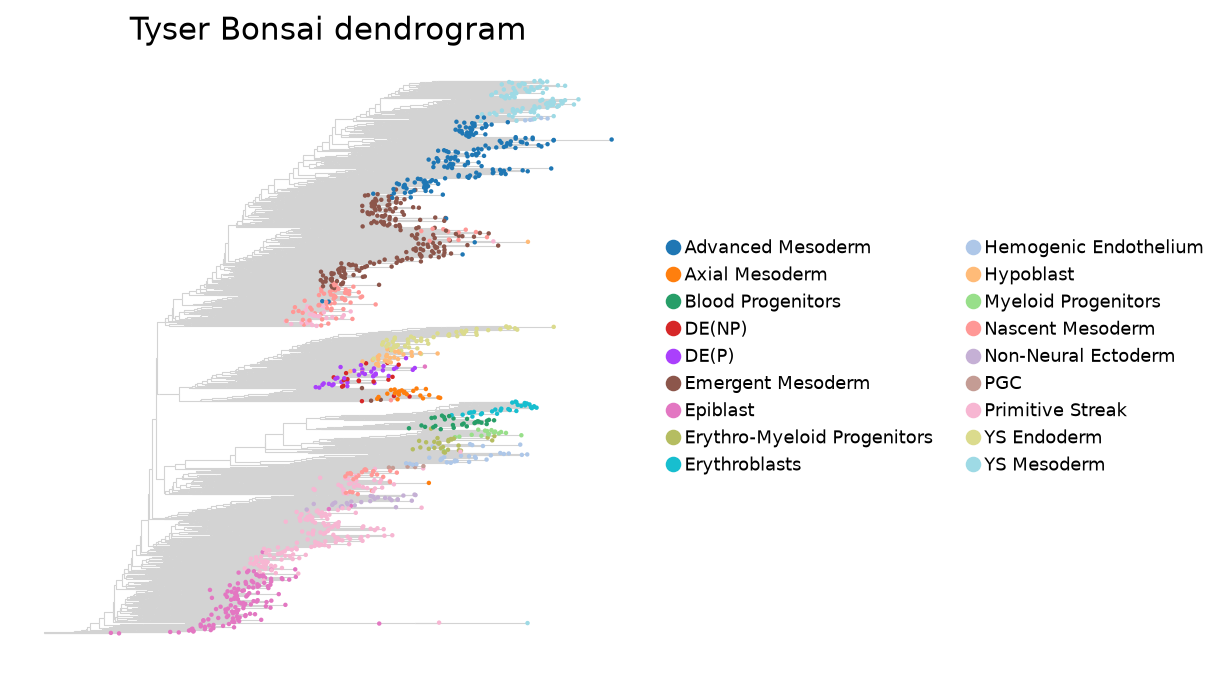

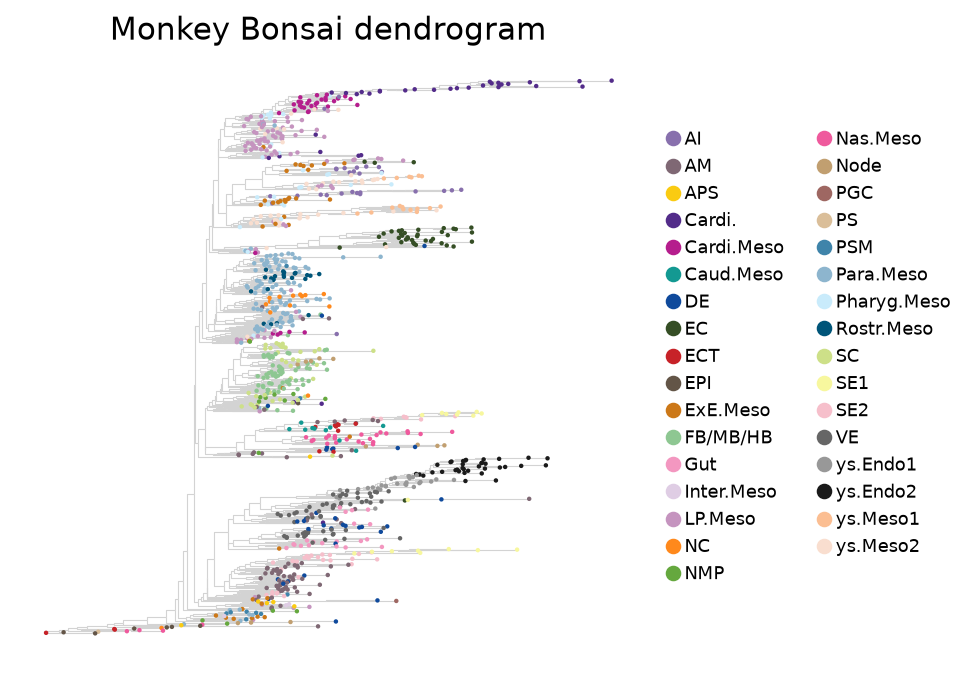

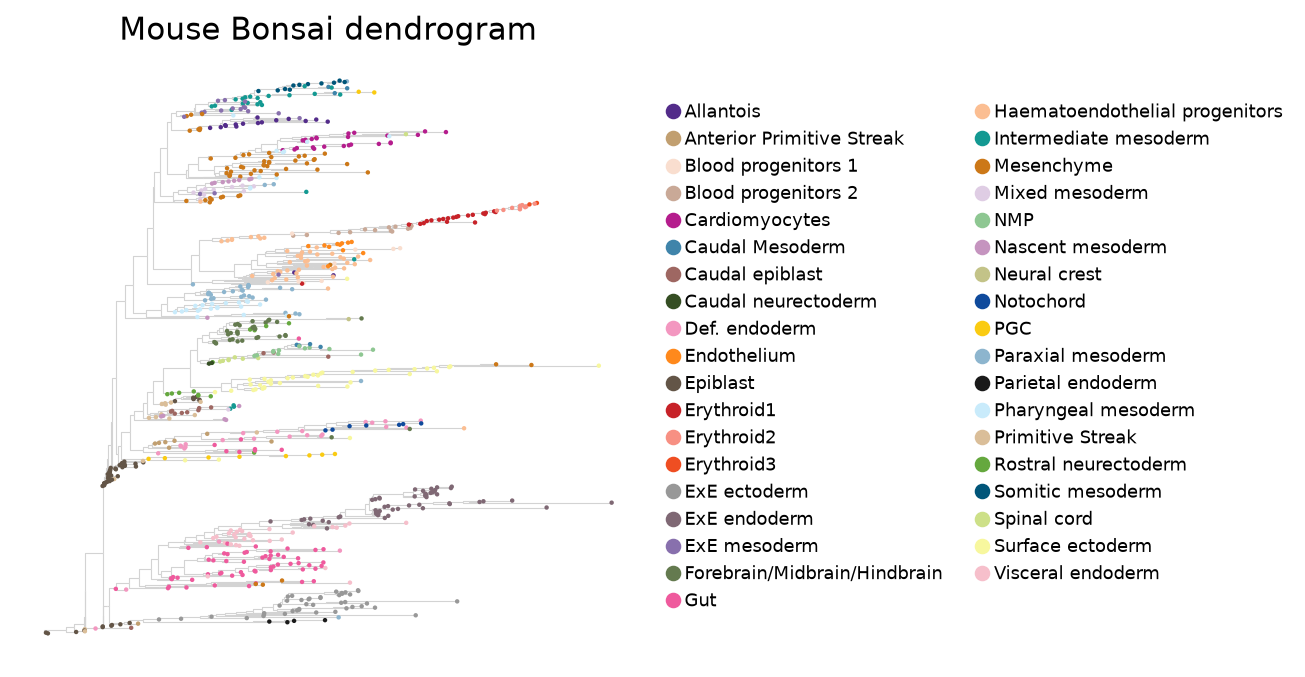

In [18]:
# ---- options -------------------------------------------------------------
FIGSIZE = (5, 5)
EDGE_COLOR = "lightgray"
EDGE_WIDTH = 0.5
LEAF_SIZE = 4  # marker area of a leaf
LEGEND_FONTSIZE = 8
LEGEND_NCOL = 2
SAVE_DIR = None  # e.g. Path("figures"); saves <title>_dendrogram.png
# --------------------------------------------------------------------------

dendrograms = [
    {
        "title": "Tyser",
        "node_data_lookup": tyser_node_data_lookup,
        "leaf_labels": tyser_leaf_labels,
        "cell_types": tyser_cell_types,
        "colors": tyser_colors,
    },
    {
        "title": "Monkey",
        "node_data_lookup": monkey_node_data_lookup,
        "leaf_labels": monkey_leaf_labels,
        "cell_types": monkey_cell_types,
        "colors": monkey_colors,
    },
    {
        "title": "Mouse",
        "node_data_lookup": mouse_node_data_lookup,
        "leaf_labels": mouse_leaf_labels,
        "cell_types": mouse_cell_types,
        "colors": mouse_colors,
    },
]

for dendrogram in dendrograms:
    node_data_lookup = dendrogram["node_data_lookup"]
    categories = dendrogram["cell_types"]
    color_pal = dict(zip(categories, dendrogram["colors"]))

    xy = {nid: nd.dendrogram_coords for nid, nd in node_data_lookup.items()}
    # one right-angle line per branch: down the parent's x, then out to the child
    segs = [
        [xy[nid], (xy[nid][0], xy[child.nodeId][1]), xy[child.nodeId]]
        for nid, nd in node_data_lookup.items()
        for child in nd.tree_node.childNodes
    ]
    leaf_ids = [nid for nid, nd in node_data_lookup.items() if nd.tree_node.isLeaf]
    leaf_xy = np.array([xy[nid] for nid in leaf_ids])
    leaf_colors = dendrogram["leaf_labels"].loc[leaf_ids].map(color_pal).to_numpy()

    fig, ax = plt.subplots(figsize=FIGSIZE)
    ax.add_collection(
        LineCollection(segs, colors=EDGE_COLOR, linewidths=EDGE_WIDTH, zorder=1)
    )
    ax.scatter(leaf_xy[:, 0], leaf_xy[:, 1], c=leaf_colors, s=LEAF_SIZE, lw=0, zorder=2)
    ax.legend(
        handles=[
            Line2D([0], [0], marker="o", linestyle="", color=color_pal[c], label=c)
            for c in categories
        ],
        loc="center left",
        bbox_to_anchor=(1.02, 0.5),
        frameon=False,
        fontsize=LEGEND_FONTSIZE,
        ncol=LEGEND_NCOL,
    )
    ax.set_title(f"{dendrogram['title']} Bonsai dendrogram")
    ax.set_axis_off()
    if SAVE_DIR is not None:
        fig.savefig(
            SAVE_DIR / f"{dendrogram['title'].lower()}_dendrogram.png",
            dpi=300,
            bbox_inches="tight",
        )
    plt.show()

# Convergence matrices

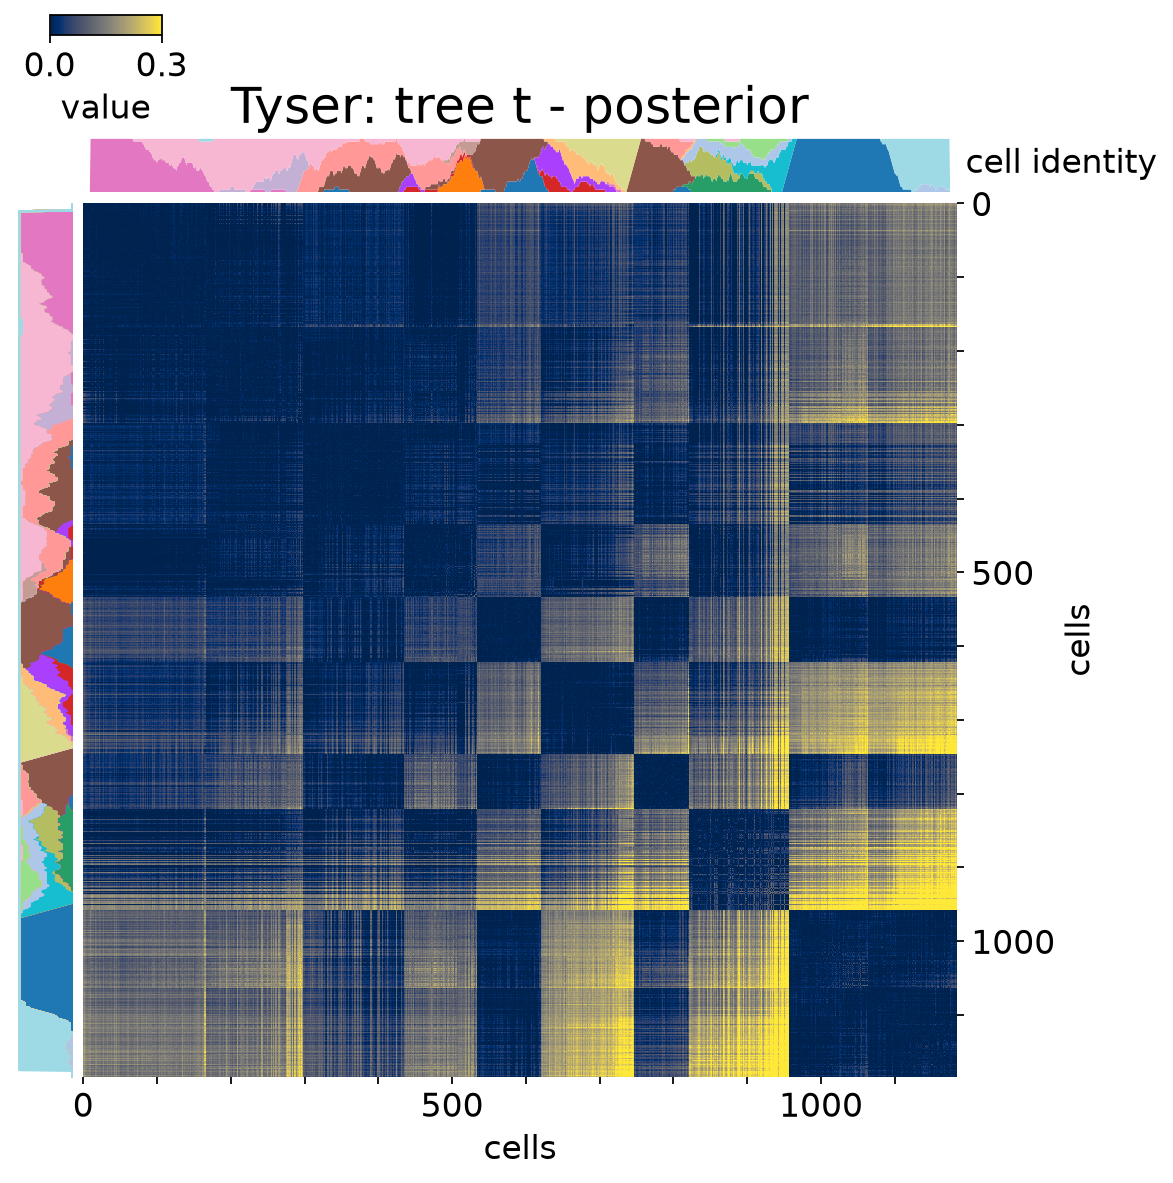

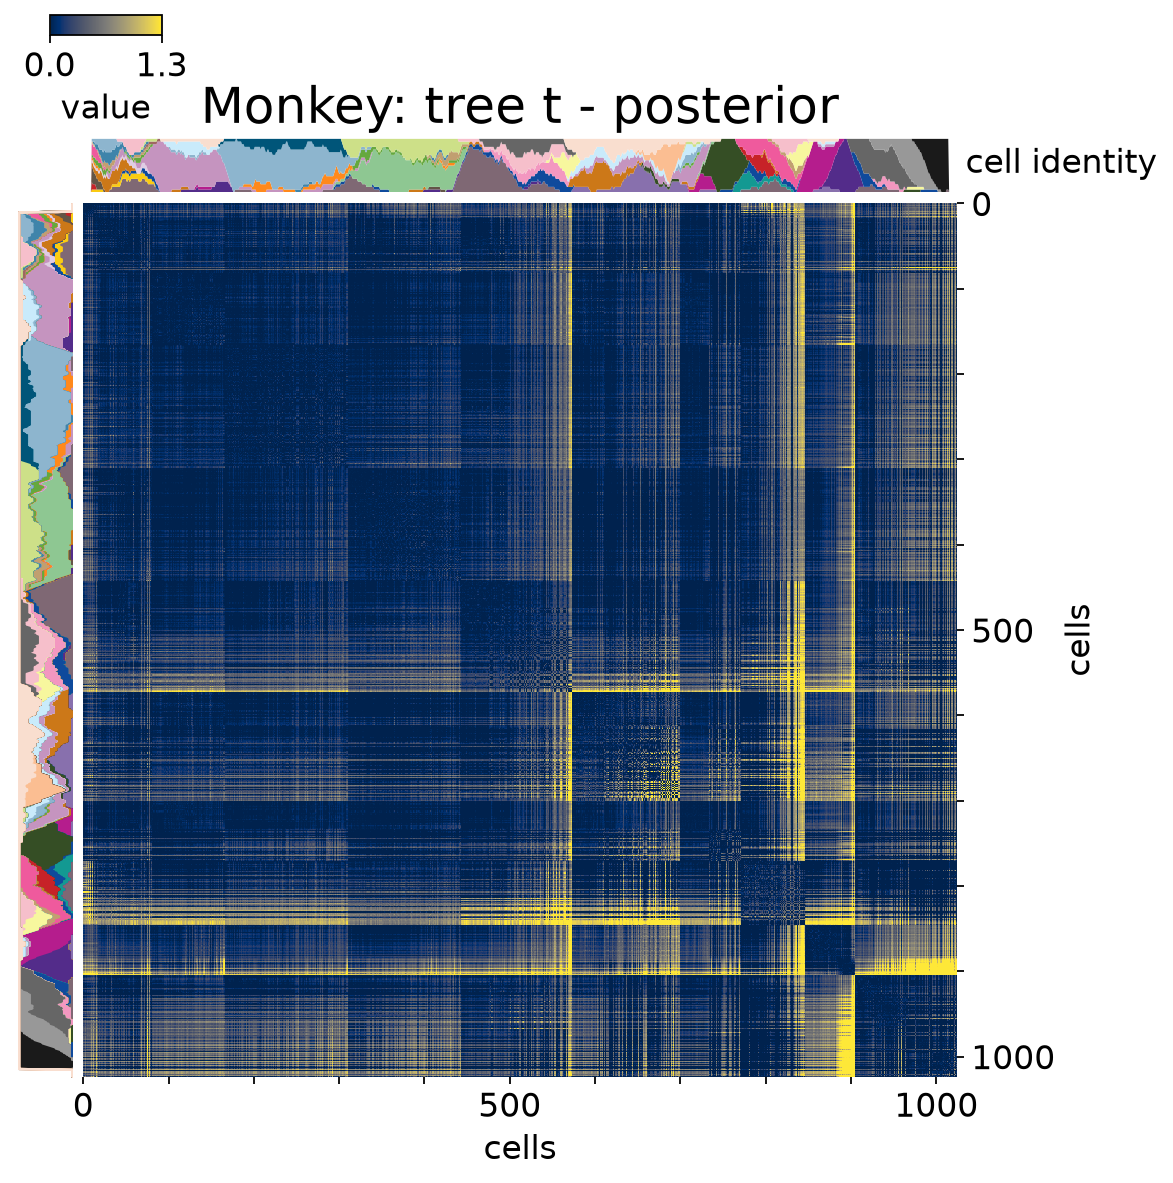

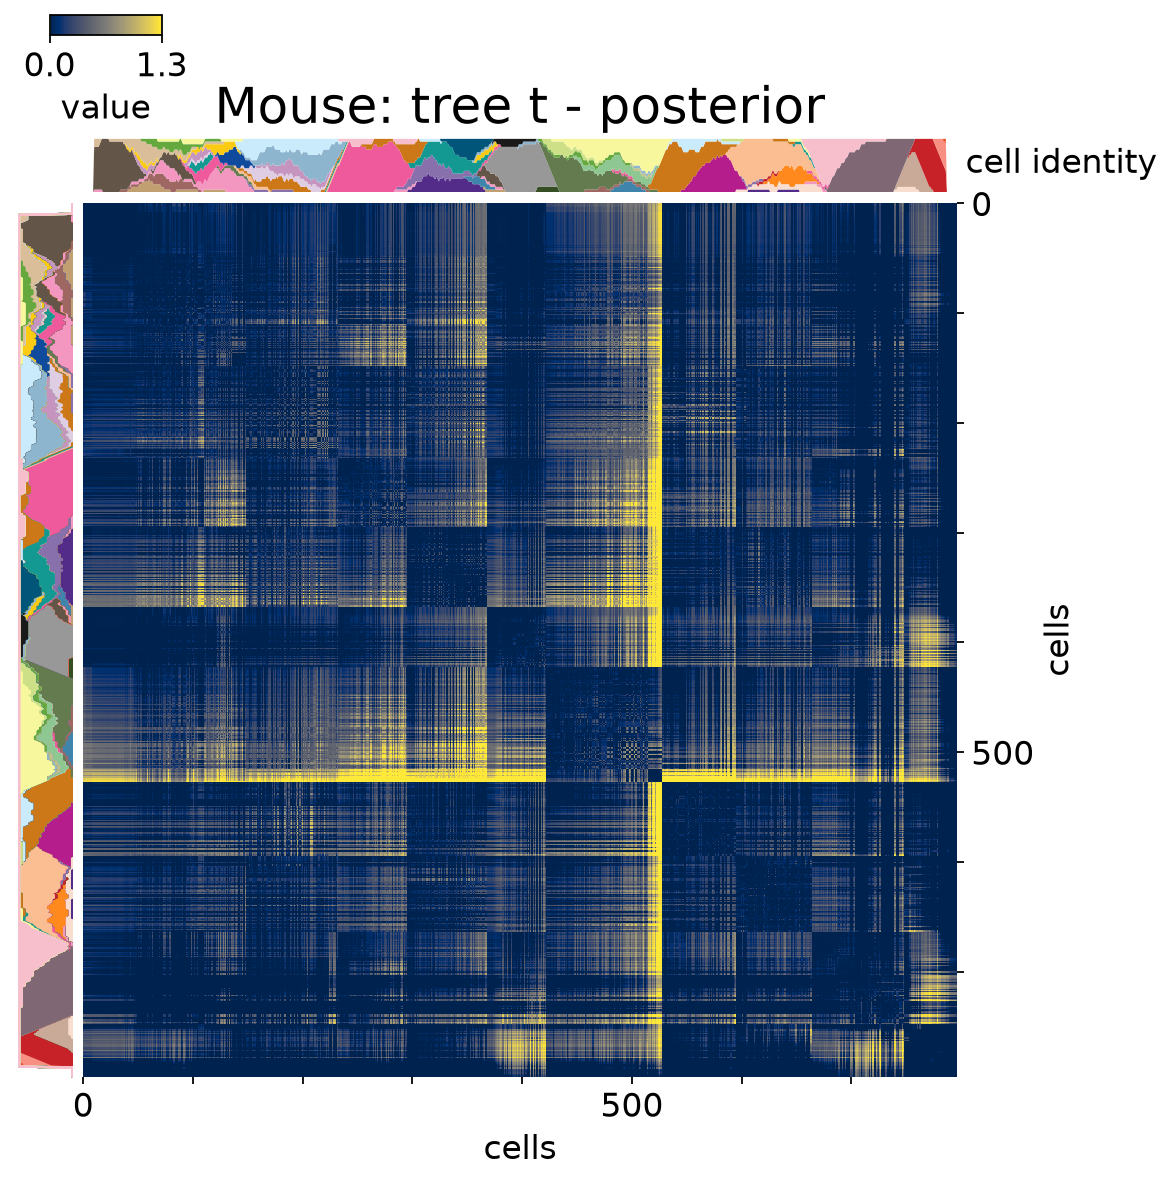

In [19]:
FONTSIZE = 15
heatmaps = [
    {
        "mat": tyser_convergence_matrix,
        "title": "Tyser: tree t - posterior",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0.0,
        "vmax": None,
        "composition": tyser_cell_composition_matrix,
        "cell_types": tyser_cell_types,
        "colors": tyser_colors,
    },
    {
        "mat": monkey_convergence_matrix,
        "title": "Monkey: tree t - posterior",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0.0,
        "vmax": None,
        "composition": monkey_cell_composition_matrix,
        "cell_types": monkey_cell_types,
        "colors": monkey_colors,
    },
    {
        "mat": mouse_convergence_matrix,
        "title": "Mouse: tree t - posterior",
        "cmap": "cividis",
        "vmin_pct": 1,
        "vmax_pct": 99,
        "vmin": 0.0,
        "vmax": None,
        "composition": mouse_cell_composition_matrix,
        "cell_types": mouse_cell_types,
        "colors": mouse_colors,
    },
]

for i, heatmap in enumerate(heatmaps):
    # make sure matrix is symmetric
    plot_mat = (heatmap["mat"] + heatmap["mat"].T) / 2

    # simple linear percentile color scaling
    vmin_pct = heatmap["vmin_pct"]
    vmax_pct = heatmap["vmax_pct"]
    if vmin_pct is None:
        vmin_pct = 0
    if vmax_pct is None:
        vmax_pct = 100
    vmin = (
        np.percentile(plot_mat, vmin_pct)
        if heatmap["vmin"] is None
        else heatmap["vmin"]
    )
    vmax = (
        np.percentile(plot_mat, vmax_pct)
        if heatmap["vmax"] is None
        else heatmap["vmax"]
    )
    norm = Normalize(vmin=vmin, vmax=vmax)

    g = sns.clustermap(
        plot_mat,
        cmap=heatmap["cmap"],
        cbar=True,
        square=False,
        xticklabels=False,
        yticklabels=False,
        row_cluster=False,
        col_cluster=False,
        figsize=(7, 7),
        rasterized=True,
        norm=norm,
    )
    ax_hm = g.ax_heatmap
    ax_hm.set_aspect("equal")
    g.ax_row_dendrogram.set_visible(False)
    g.ax_col_dendrogram.set_visible(False)
    g.cax.set_visible(False)

    ax_hm.set_position([0.1, 0.08, 0.78, 0.78])
    pos = ax_hm.get_position()

    n = plot_mat.shape[1]
    n_rows = plot_mat.shape[0]
    x = np.arange(n)
    y = np.arange(n_rows)

    tick_x = np.arange(0, n, 100)
    tick_x_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_x]
    ax_hm.set_xticks(tick_x)
    ax_hm.set_xticklabels(tick_x_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="x", which="major", length=3, direction="out")
    ax_hm.grid(False)

    tick_y = np.arange(0, n_rows, 100)
    tick_y_labels = [str(int(t)) if t % 500 == 0 else "" for t in tick_y]
    ax_hm.set_yticks(tick_y)
    ax_hm.set_yticklabels(tick_y_labels, fontsize=FONTSIZE)
    ax_hm.tick_params(axis="y", which="major", length=3, direction="out")
    ax_hm.set_xlabel("cells", fontsize=FONTSIZE)
    ax_hm.set_ylabel("cells", fontsize=FONTSIZE)

    ax_top = g.fig.add_axes([pos.x0, pos.y1 + 0.01, pos.width, 0.05])
    ax_top.stackplot(
        x,
        heatmap["composition"][:-1, :],
        labels=heatmap["cell_types"],
        colors=heatmap["colors"],
    )
    ax_top.set_xlim(ax_hm.get_xlim())
    ax_top.axis("off")
    ax_top.text(
        1.01,
        0.5,
        "cell identity",
        transform=ax_top.transAxes,
        ha="left",
        va="center",
        rotation=0,
        fontsize=FONTSIZE,
        clip_on=False,
    )

    ax_left = g.fig.add_axes([pos.x0 - 0.06, pos.y0, 0.05, pos.height])
    cumulative = np.cumsum(heatmap["composition"][:-1, :], axis=0)
    prev = np.zeros(n_rows)
    for k in range(cumulative.shape[0]):
        ax_left.fill_betweenx(y, prev, cumulative[k], color=heatmap["colors"][k])
        prev = cumulative[k]
    ax_left.set_xlim(1, 0)
    ax_left.set_ylim(ax_hm.get_ylim())
    ax_left.axis("off")

    ax_top.set_title(heatmap["title"], fontsize=FONTSIZE * 1.5)

    mappable = ScalarMappable(norm=norm, cmap=heatmap["cmap"])
    mappable.set_array([])
    cax = g.fig.add_axes([pos.x0 - 0.03, 1.01, 0.1, 0.018])
    cb = g.fig.colorbar(mappable, cax=cax, orientation="horizontal")
    cb.set_label("value", fontsize=FONTSIZE, labelpad=4)
    if vmin < 0 < vmax:
        cb.set_ticks([vmin, 0, vmax], labels=[f"{vmin:.1f}", "0", f"{vmax:.1f}"])
    else:
        cb.set_ticks([vmin, vmax], labels=[f"{vmin:.1f}", f"{vmax:.1f}"])
    cb.ax.tick_params(labelsize=FONTSIZE)

    plt.show()
    plt.close()
    gc.collect()